In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random as rn
import ast

path       = r"/workspace/qgi\trojan\Numbeo\Cost of Living\Cost of Living Index_PATTERNS_DF.csv"
indexName  = path.split("\\")[-1].split(".")[0].split("_")[0]
patternLen = rn.choice([8, 9, 10])

def yearsAdjuster(years: list, patternLen: int, c1pattIndex: list, c1pattValues: list):
    j               = 0
    newC1pattValues = []
    
    for i in range(len(years)):
        if j < patternLen and j < len(c1pattIndex):
            if years[i] != c1pattIndex[j]:
                newC1pattValues.append(np.nan)
            else:
                newC1pattValues.append(c1pattValues[j])
                j += 1
        else:
            newC1pattValues.append(np.nan)

    return newC1pattValues

df = pd.read_csv(path)
df = df.drop("Unnamed: 0", axis = 1)
df.head()

,Pattern Country,Match Country,Index,Pattern Values,Pattern Index,Match Values,Match Index,Rank,Score,Correlation Score,Euclidean Score,MAPE Score,DTW Score,CBD Score,Pattern Length
0,Afghanistan,Albania,Cost of Living Index,"[24.24, 26.33, 20.37]","[2020, 2021, 2022]","[48.64, 48.96, 41.95]","[2013, 2014, 2015]",Platinum,0.05,0.95,39.66,0.98,39.66,0.51,3
1,Afghanistan,Algeria,Cost of Living Index,"[24.24, 26.33, 20.37]","[2020, 2021, 2022]","[40.64, 41.49, 39.11]","[2012, 2013, 2014]",Platinum,0.00,1.00,29.15,0.72,29.15,0.51,3
2,Afghanistan,Argentina,Cost of Living Index,"[24.24, 26.33, 20.37]","[2020, 2021, 2022]","[66.85, 67.12, 64.09]","[2014, 2015, 2016]",Platinum,0.04,0.96,73.42,1.82,73.42,0.51,3
3,Afghanistan,Armenia,Cost of Living Index,"[24.24, 26.33, 20.37]","[2020, 2021, 2022]","[32.51, 32.84, 31.68]","[2019, 2020, 2021]",Platinum,0.00,1.00,15.45,0.38,15.45,0.51,3
4,Afghanistan,Australia,Cost of Living Index,"[24.24, 26.33, 20.37]","[2020, 2021, 2022]","[80.66, 84.3, 72.08]","[2017, 2018, 2019]",Platinum,0.00,1.00,96.01,2.36,96.01,0.51,3


/workspace\AppData\Local\Temp\ipykernel_30540\1520496405.py:72: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use("seaborn-darkgrid")


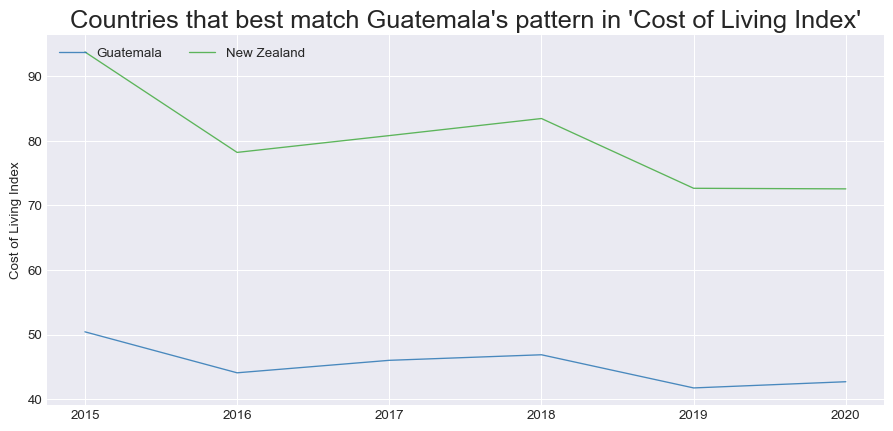

In [50]:
country1 = rn.choice(list(set(df["Pattern Country"])))
country2 = rn.choice(list(set(df["Match Country"])))

c1df      = df[df["Pattern Country"] == country1]
#patternLen = list(set(c1df["Pattern Length"]))
patLength = rn.choice(list(set(c1df["Pattern Length"])))
c1df      = c1df[c1df["Pattern Length"] == patLength]  # <
c1df      = c1df[c1df["Correlation Score"] == max(list(c1df["Correlation Score"]))]
c1df      = c1df[c1df["Pattern Index"] == rn.choice(list(set(c1df["Pattern Index"])))]    # <


min1, min2, max1, max2 = [None, None, None, None]
for i in range(len(c1df)):
    if min1 is None:
        min1 = min(ast.literal_eval(list(c1df["Pattern Index"])[i]))
    else:
        min1 = min(min(ast.literal_eval(list(c1df["Pattern Index"])[i])), min1)

    if min2 is None:
        min2 = min(ast.literal_eval(list(c1df["Match Index"])[i]))
    else:
        min2 = min(min(ast.literal_eval(list(c1df["Match Index"])[i])), min2)

    if max1 is None:
        max1 = max(ast.literal_eval(list(c1df["Pattern Index"])[i]))
    else:
        max1 = max(max(ast.literal_eval(list(c1df["Pattern Index"])[i])), max1)

    if max2 is None:
        max2 = max(ast.literal_eval(list(c1df["Match Index"])[i]))
    else:
        max2 = max(max(ast.literal_eval(list(c1df["Match Index"])[i])), max2)

years = list(range(min(min1, min2), max(max1, max2) + 1))


c1pattIndex  = ast.literal_eval(list(c1df["Pattern Index"])[0])
c1pattValues = ast.literal_eval(list(c1df["Pattern Values"])[0])

C1Vals       = yearsAdjuster(years, patternLen, c1pattIndex, c1pattValues)


matchCountries = []
matchCountries.append(years)
matchCountries.append(C1Vals)

for i in range(len(c1df)):
    c2pattIndex  = ast.literal_eval(list(c1df["Match Index"])[i])
    c2pattValues = ast.literal_eval(list(c1df["Match Values"])[i])
    matchCountries.append(yearsAdjuster(years, patternLen, c2pattIndex, c2pattValues))


colNames = []
colNames.append("Years")
colNames.append(country1)
for c2s in list(set(c1df["Match Country"])):
    colNames.append(c2s)


dfViz         = pd.DataFrame(matchCountries).T
dfViz.columns = colNames


endPoints = []
endYears  = []
for col in list(dfViz)[1:]:
    endPoints.append(list(dfViz[col])[dfViz[col].last_valid_index()])
    endYears.append(list(dfViz["Years"])[dfViz[col].last_valid_index()])
endYears = endYears[1:]


plt.style.use("seaborn-darkgrid")
my_dpi = 96
plt.figure(figsize = (1080 / my_dpi, 480 / my_dpi), dpi = my_dpi)
palette = plt.get_cmap("Set1")
 
# Plot multiple lines
num = 0
for column in dfViz.drop("Years", axis = 1):
    num += 1
    plt.plot(dfViz["Years"], dfViz[column], marker = "", color = palette(num), linewidth = 1, alpha = 0.9, label = column)

plt.legend(loc = 2, ncol = 2)
 
plt.title("Countries that best match " + country1 + "'s pattern in '" + indexName + "'", loc = "center", fontsize = 19, fontweight = 0)
#plt.xlabel("Time")
plt.ylabel(indexName)

plt.show()